# Quantum Dynamics: Wave Packets and Tunneling

The time-dependent Schrödinger equation (in units with $\hbar = m = 1$)

$$
i\,\frac{\partial \psi}{\partial t} = H \psi, \qquad H = -\frac{1}{2}\frac{\partial^2}{\partial x^2} + V(x)
$$

is a demanding problem for time stepping schemes: the wave function is complex, the operator is stiff,
and the norm $\int |\psi|^2 dx$ must be conserved. For a time-independent Hamiltonian, however, the solution
is known in closed form,

$$
\psi(t) = e^{-i H t}\, \psi(0).
$$

The exponential integrator of *numgrids*, `evolve(..., method="expm")`, evaluates exactly this: no time
steps, no time stepping error, and the norm is conserved to round-off.

In this notebook we

1. let a free wave packet spread and compare with the exact solution,
2. send a wave packet against a potential barrier and watch it **tunnel**,
3. follow a coherent state in a harmonic oscillator through one period.

## Setup

We use a periodic grid: Fourier differentiation is spectrally accurate and resolves the oscillations of a
moving wave packet uniformly over the whole domain. The box is large enough that the packet never reaches
its ends.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numgrids import *

grid = Grid(x=periodic(512, -60, 60))
x = grid.coords
T = -0.5 * grid.diff_operator(2)        # kinetic energy


def wave_packet(x0, k0, sigma=1.5):
    psi = np.exp(-(x - x0)**2 / (4 * sigma**2) + 1j * k0 * x)
    return psi / grid.norm(psi)         # normalized: integral of |psi|^2 is 1

print(grid)

Grid(shape=(512,), ndims=1, axes=[
    EquidistantAxis(num_points=512, low=-60, high=60, periodic=True, name='x')
])


## A Free Wave Packet

Without a potential, a Gaussian wave packet with mean momentum $k_0$ moves with the velocity $k_0$ and
spreads: its width grows as

$$
\sigma(t) = \sigma_0 \sqrt{1 + \frac{t^2}{4 \sigma_0^4}} .
$$

`evolve` takes the operator $-iH$ as the right-hand side of $\partial_t \psi = -iH\psi$. `grid.inner` and
`grid.norm` compute the expectation values.

In [2]:
sigma0, k0 = 1.5, 2.0
psi0 = wave_packet(x0=-20, k0=k0, sigma=sigma0)
times = np.linspace(0, 16, 5)

free = evolve(grid, -1j * T, psi0, t_span=(0, 16), t_eval=times, method="expm")

print("   t    norm            <x>       exact     width     exact")
for t, psi in zip(free.t, free.u):
    mean = grid.inner(psi, x * psi).real
    width = np.sqrt(grid.inner(psi, (x - mean)**2 * psi).real)
    print(f"{t:5.1f}   {grid.norm(psi):.12f}  {mean:8.4f}  {-20 + k0 * t:8.4f}"
          f"  {width:8.5f}  {sigma0 * np.sqrt(1 + t**2 / (4 * sigma0**4)):8.5f}")

   t    norm            <x>       exact     width     exact
  0.0   1.000000000000  -20.0000  -20.0000   1.50000   1.50000
  4.0   1.000000000000  -12.0000  -12.0000   2.00693   2.00693
  8.0   1.000000000000   -4.0000   -4.0000   3.05959   3.05959
 12.0   1.000000000000    4.0000    4.0000   4.27200   4.27200
 16.0   1.000000000000   12.0000   12.0000   5.54026   5.54026


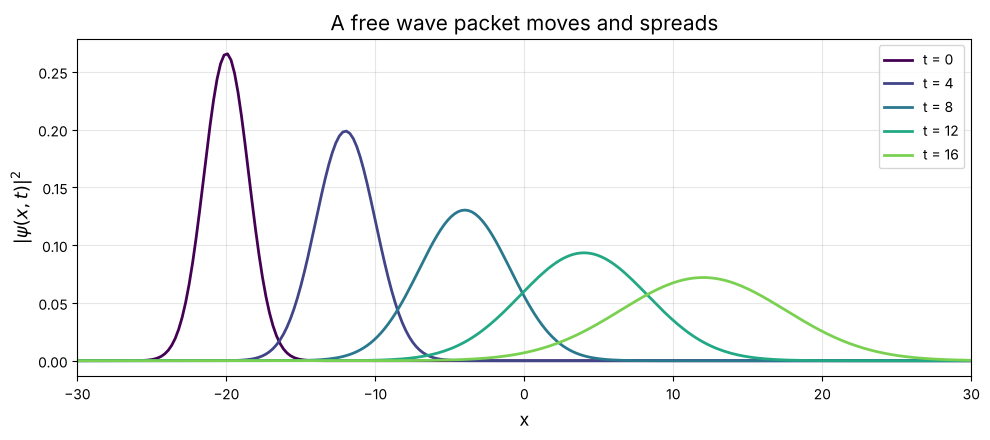

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cmap = plt.cm.viridis
for i, (t, psi) in enumerate(zip(free.t, free.u)):
    ax.plot(x, np.abs(psi)**2, color=cmap(i / len(times)), linewidth=2, label=f"t = {t:.0f}")
ax.set_xlim(-30, 30)
ax.set_xlabel("x", fontsize=13)
ax.set_ylabel(r"$|\psi(x, t)|^2$", fontsize=13)
ax.set_title("A free wave packet moves and spreads", fontsize=15)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Tunneling Through a Barrier

Now we put a potential barrier in the way of the wave packet. Its mean energy $k_0^2/2 = 2$ is *below*
the top of the barrier, $V_0 = 2.5$. A classical particle would be reflected. The wave packet splits: one
part is reflected, the other tunnels through.

The potential is an array on the grid, and adding it to the kinetic energy operator gives the
Hamiltonian.

In [4]:
V0, width = 2.5, 0.6
V = V0 * np.exp(-x**2 / (2 * width**2))
H = T + V

times = np.linspace(0, 24, 241)
result = evolve(grid, -1j * H, psi0, t_span=(0, 24), t_eval=times, method="expm")
density = np.abs(result.u)**2           # shape (time, space)

print("norm at the end:", grid.norm(result.final))

norm at the end: 0.9999999999999928


The output times are equally spaced, so the matrix exponential is computed only once and reused for all 240
steps.

### Space-time picture

The probability density as a function of position and time shows the whole process: the packet
approaches the barrier at $x = 0$, interferes with its own reflection, and separates into a reflected and
a transmitted packet.

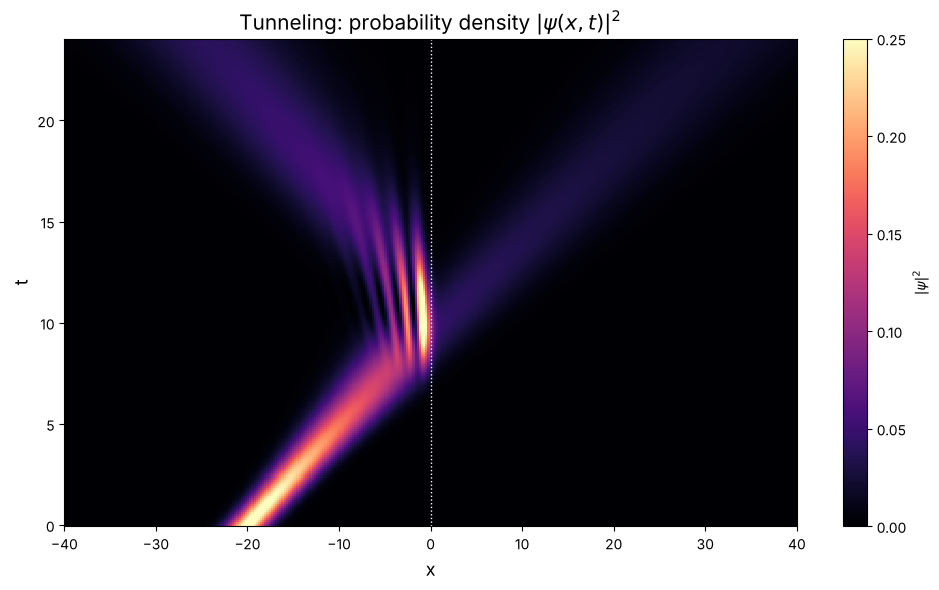

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.pcolormesh(x, times, density, cmap="magma", shading="auto", vmax=0.25)
ax.axvline(0, color="white", linestyle=":", linewidth=1)
ax.set_xlim(-40, 40)
ax.set_xlabel("x", fontsize=13)
ax.set_ylabel("t", fontsize=13)
ax.set_title("Tunneling: probability density $|\\psi(x, t)|^2$", fontsize=15)
fig.colorbar(im, ax=ax, label=r"$|\psi|^2$")
fig.tight_layout()
plt.show()

### Transmission probability

The probability of finding the particle behind the barrier is the integral of $|\psi|^2$ over $x > 0$. We
compare with the transmission of the individual momentum components of the packet: a plane wave with wave
number $k$ is an eigenstate of the scattering problem, and its transmission probability $T(k)$ follows
from a **boundary value problem** for the stationary Schrödinger equation, which `Operator.solve` handles
with Robin (radiation) conditions. The wave packet average $\int T(k)\,|\tilde\psi(k)|^2\,dk$ must agree
with the result of the time evolution.

In [6]:
behind = x > 0
transmitted = np.array([grid.integrate(d * behind) for d in density])
print(f"transmission probability from the time evolution: {transmitted[-1]:.6f}")


def transmission(k, L=8.0, n=160):
    # Stationary scattering on [-L, L]: -psi''/2 + V psi = (k^2/2) psi, with
    #   psi = exp(ikx) + r exp(-ikx) on the left:   psi' + ik psi = 2ik exp(ikx)   (incoming wave)
    #   psi = t exp(ikx)             on the right:  psi' - ik psi = 0              (outgoing wave)
    # The outward normal derivative is -psi' on the left and +psi' on the right.
    g = Grid(x=chebyshev(n, -L, L))
    xs = g.coords
    A = -0.5 * g.diff_operator(2) + V0 * np.exp(-xs**2 / (2 * width**2)) - k**2 / 2
    psi = A.solve(0, bcs={"x_low": Robin(1j * k, -1, 2j * k * np.exp(-1j * k * L)),
                          "x_high": Robin(-1j * k, 1, 0)})
    return abs(psi[-1])**2


ks = np.linspace(k0 - 1.2, k0 + 1.2, 121)
T_k = np.array([transmission(k) for k in ks])
weight = np.exp(-2 * sigma0**2 * (ks - k0)**2)          # |psi(k)|^2 of the Gaussian packet
T_packet = np.sum(T_k * weight) / np.sum(weight)
print(f"transmission probability from stationary scattering: {T_packet:.6f}")

transmission probability from the time evolution: 0.358402


transmission probability from stationary scattering: 0.358397


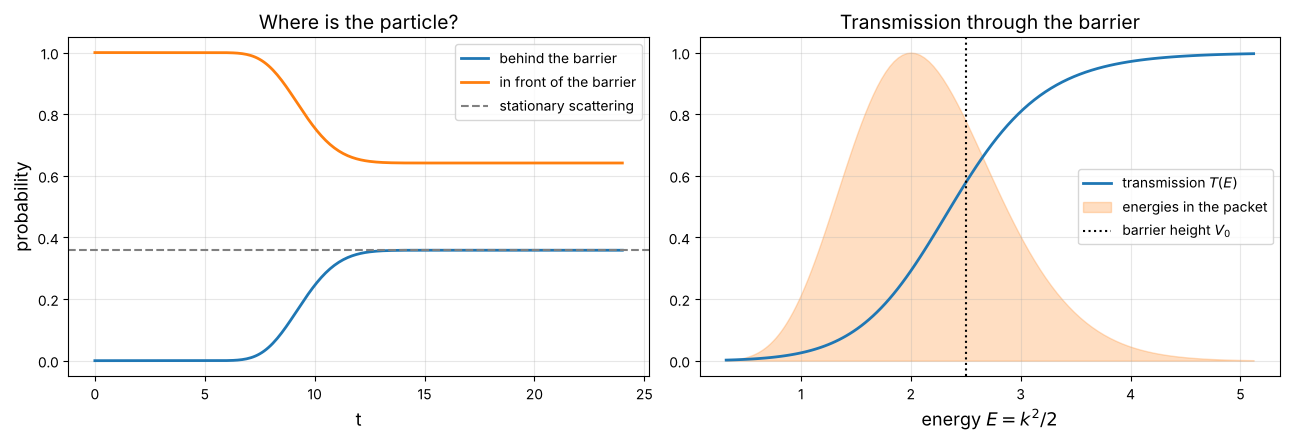

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(times, transmitted, linewidth=2, label="behind the barrier")
ax1.plot(times, 1 - transmitted, linewidth=2, label="in front of the barrier")
ax1.axhline(T_packet, color="gray", linestyle="--", label="stationary scattering")
ax1.set_xlabel("t", fontsize=13)
ax1.set_ylabel("probability", fontsize=13)
ax1.set_title("Where is the particle?", fontsize=14)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

ax2.plot(ks**2 / 2, T_k, linewidth=2, label="transmission $T(E)$")
ax2.fill_between(ks**2 / 2, weight / weight.max(), alpha=0.25, color="C1", label="energies in the packet")
ax2.axvline(V0, color="k", linestyle=":", label="barrier height $V_0$")
ax2.set_xlabel("energy $E = k^2/2$", fontsize=13)
ax2.set_title("Transmission through the barrier", fontsize=14)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

## A Coherent State in the Harmonic Oscillator

Finally a classic: in the harmonic potential $V = x^2/2$, a displaced ground state (a *coherent state*)
oscillates like a classical particle, $\langle x \rangle (t) = x_0 \cos t$, without changing its shape.
After one period $2\pi$ the wave function returns to its initial state, up to the phase factor $-1$ that
comes from the zero-point energy.

In [8]:
H_osc = T + 0.5 * x**2
x0 = 5.0
coherent0 = np.pi**-0.25 * np.exp(-(x - x0)**2 / 2)

times = np.linspace(0, 2 * np.pi, 201)
osc = evolve(grid, -1j * H_osc, coherent0, t_span=(0, 2 * np.pi), t_eval=times, method="expm")

mean_x = np.array([grid.inner(psi, x * psi).real for psi in osc.u])
print("largest deviation of <x> from x0 cos(t):", np.max(np.abs(mean_x - x0 * np.cos(times))))
print("overlap with the initial state after one period:", grid.inner(coherent0, osc.final))

largest deviation of <x> from x0 cos(t): 2.0250467969162855e-13
overlap with the initial state after one period: (-1.0000000000000209+1.6912993115952435e-14j)


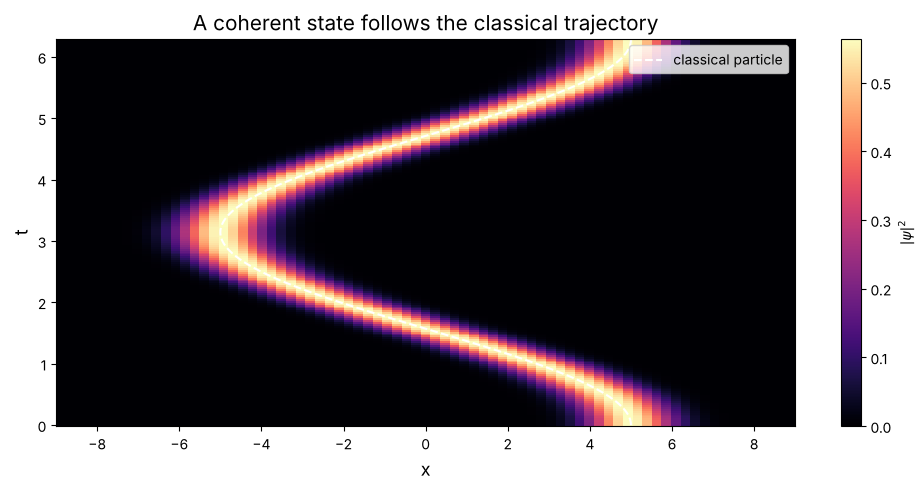

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(x, times, np.abs(osc.u)**2, cmap="magma", shading="auto")
ax.plot(x0 * np.cos(times), times, color="white", linestyle="--", linewidth=1.5, label="classical particle")
ax.set_xlim(-9, 9)
ax.set_xlabel("x", fontsize=13)
ax.set_ylabel("t", fontsize=13)
ax.set_title("A coherent state follows the classical trajectory", fontsize=15)
ax.legend(loc="upper right", fontsize=10)
fig.colorbar(im, ax=ax, label=r"$|\psi|^2$")
fig.tight_layout()
plt.show()

## Why Not a Standard Time Stepper?

Explicit Runge-Kutta methods also integrate the Schrödinger equation, but they need many small steps for
this stiff operator and conserve the norm only up to their tolerance. The exponential integrator is exact
for the discretized problem:

In [10]:
import time

for label, kwargs in [("expm", dict(method="expm")),
                      ("RK45, rtol=1e-6", dict(method="RK45", rtol=1e-6, atol=1e-9)),
                      ("DOP853, rtol=1e-10", dict(method="DOP853", rtol=1e-10, atol=1e-12))]:
    start = time.perf_counter()
    res = evolve(grid, -1j * H, psi0, t_span=(0, 24), t_eval=[0, 24], **kwargs)
    elapsed = time.perf_counter() - start
    error = grid.norm(res.final - result.final)
    steps = "" if res.sol is None else f"{res.sol.nfev:6d} evaluations of the right-hand side"
    print(f"{label:20s} norm - 1 = {grid.norm(res.final) - 1:9.1e}   "
          f"difference to expm = {error:8.1e}   {steps}")

expm                 norm - 1 =  -1.7e-15   difference to expm =  7.4e-14   


RK45, rtol=1e-6      norm - 1 =  -1.3e-07   difference to expm =  9.1e-06     9038 evaluations of the right-hand side


DOP853, rtol=1e-10   norm - 1 =  -1.0e-12   difference to expm =  7.4e-10     4460 evaluations of the right-hand side


## Summary

* `evolve(grid, -1j * H, psi0, t_span, method="expm")` solves the time-dependent Schrödinger equation
  without time stepping error and conserves the norm to round-off.
* Potentials are arrays on the grid; `T + V` is the Hamiltonian.
* `grid.inner` and `grid.norm` give expectation values and probabilities.
* The same operators solve the stationary scattering problem with `Operator.solve` and Robin conditions.